In [13]:
import os
from arviz import plot_posterior
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl

## Exercise 1: in class we tried to find when and if there was a change in the arrival rate of text massaging per day.
### Suppose you suspect there were actually three different rates (that is, two different witching points).
#### In the next exercise, follow the same line of thought of the model with two different rates and apply it for differetn three different rates.

#### The goal is to understand it there are more than two switching points.

## Instructions:

### 1. Load the data. First upload it to the drive and then mount it into colab.
### 2. Build a pymc model like we did in class. This means choosing priors, likelihood, number of MCMC samples, and constructing determinstic functions with 'switch'.
### 3. Analyzing the posterior. Extracing the posterior samples and visualzing them.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


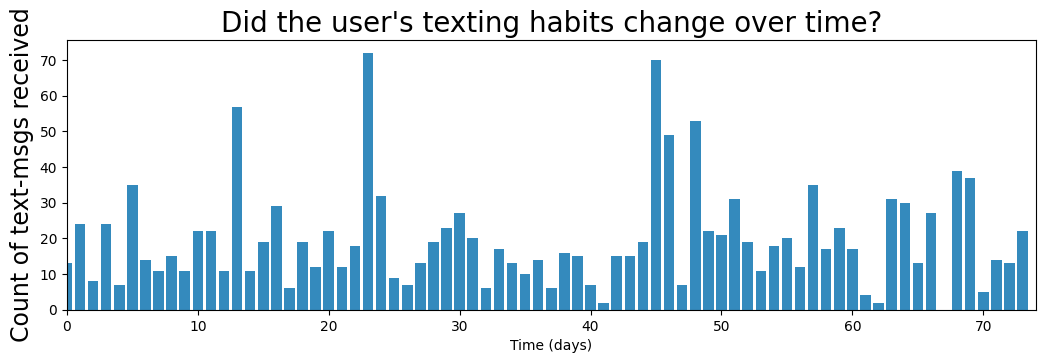

In [14]:
%matplotlib inline
from IPython.core.pylabtools import figsize
figsize(12.5, 3.5)

from google.colab import drive
drive.mount('/content/drive')

colab = True #fix to you
if colab:
  count_data = np.loadtxt("/content/drive/MyDrive/מודליים ביסיאניים/txtdata.csv")
else:
  count_data = np.loadtxt("../data/txtdata.csv")


n_count_data = len(count_data)
plt.bar(np.arange(n_count_data), count_data, color="#348ABD")
plt.xlabel("Time (days)")
plt.ylabel("Count of text-msgs received", fontsize = 17)
plt.title("Did the user's texting habits change over time?", fontsize = 20)
plt.xlim(0, n_count_data);

In [15]:
count_data.shape

(74,)

In [16]:
with pm.Model() as model:
    alpha = 1.0/count_data.mean()


    lambdas = pm.Exponential("lambda_priors", alpha, shape  = 3)


    tau1 = pm.DiscreteUniform("tau1", lower=1, upper=n_count_data - 2)
    tau2 = pm.DiscreteUniform("tau2", lower=tau1 + 1, upper=n_count_data - 1)

    idx = np.arange(n_count_data) # Index
    lambda_ = pm.Deterministic(
        "lambda_",
        pm.math.switch(
            idx < tau1,
            lambdas[0],
            pm.math.switch(idx < tau2, lambdas[1], lambdas[2])
        )
    )

    observation = pm.Poisson("obs", lambda_, observed=count_data)

    step = pm.Metropolis()
    trace = pm.sample(5000, tune=1000, step=step)




Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [17]:
## Extracting the samples
lambda_1_samples = trace.posterior["lambda_priors"].values[:, :, 0].flatten()
lambda_2_samples = trace.posterior["lambda_priors"].values[:, :, 1].flatten()
lambda_3_samples = trace.posterior["lambda_priors"].values[:, :, 2].flatten()

tau1_samples = np.array(trace.posterior["tau1"]).flatten()
tau2_samples = np.array(trace.posterior["tau2"]).flatten()


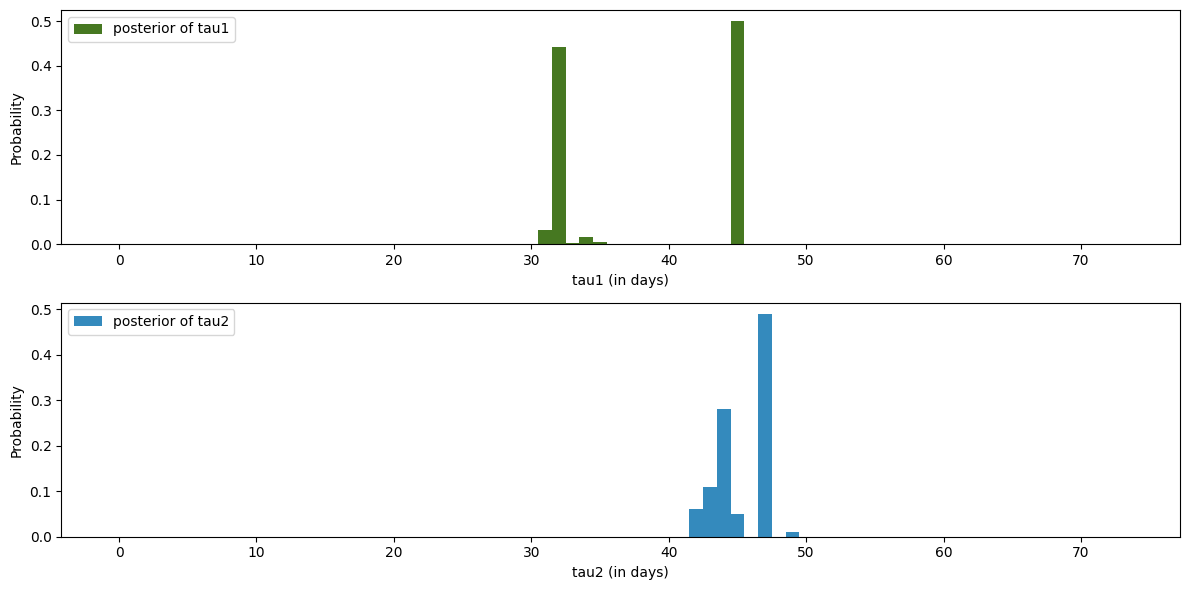

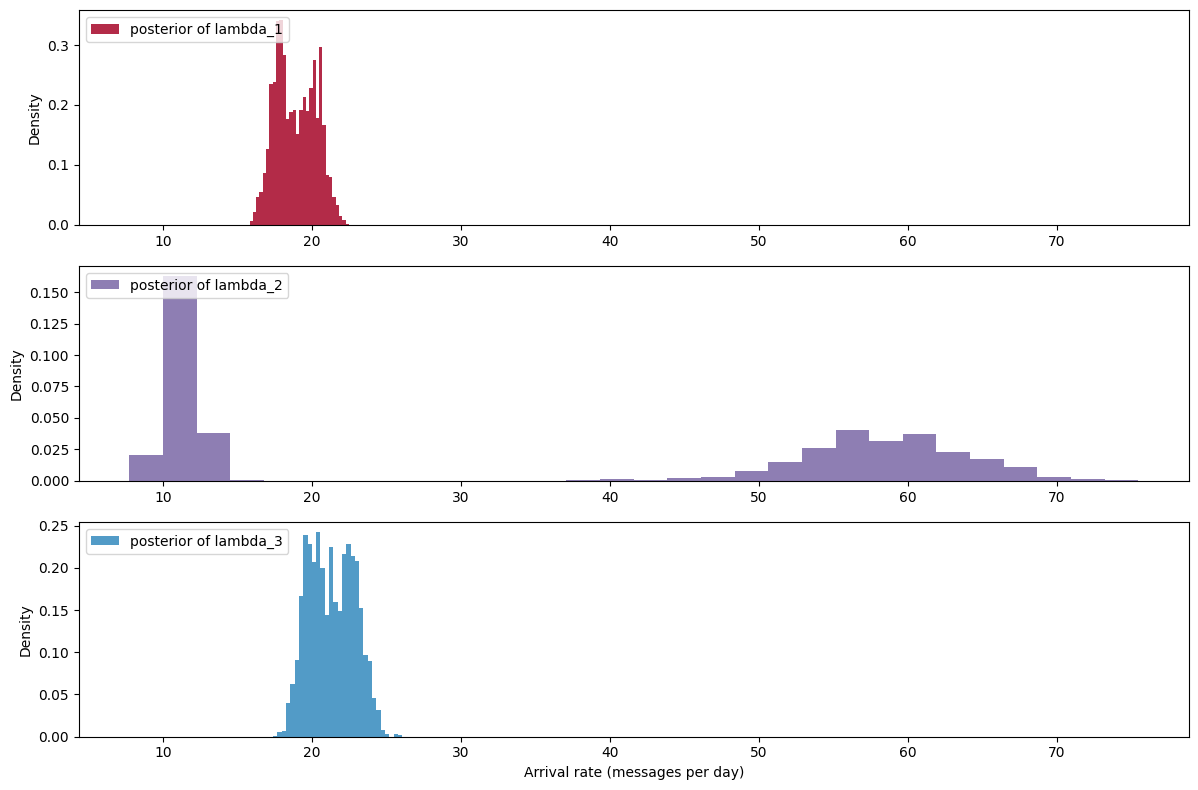

In [18]:
### Visualizing the samples
plt.figure(figsize=(12, 6))

plt.subplot(211)
w = np.ones_like(tau1_samples) / len(tau1_samples)
plt.hist(tau1_samples, bins=np.arange(n_count_data + 1) - 0.5,
         weights=w, color="#467821", label="posterior of tau1")
plt.xlabel("tau1 (in days)")
plt.ylabel("Probability")
plt.legend(loc="upper left")

plt.subplot(212)
w = np.ones_like(tau2_samples) / len(tau2_samples)
plt.hist(tau2_samples, bins=np.arange(n_count_data + 1) - 0.5,
         weights=w, color="#348ABD", label="posterior of tau2")
plt.xlabel("tau2 (in days)")
plt.ylabel("Probability")
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 8))

plt.subplot(311)
plt.hist(lambda_1_samples, bins=30, density=True,
         color="#A60628", alpha=0.85, label="posterior of lambda_1")
plt.ylabel("Density")
plt.legend(loc="upper left")

plt.subplot(312, sharex=plt.gcf().axes[0])
plt.hist(lambda_2_samples, bins=30, density=True,
         color="#7A68A6", alpha=0.85, label="posterior of lambda_2")
plt.ylabel("Density")
plt.legend(loc="upper left")

plt.subplot(313, sharex=plt.gcf().axes[0])
plt.hist(lambda_3_samples, bins=30, density=True,
         color="#348ABD", alpha=0.85, label="posterior of lambda_3")
plt.xlabel("Arrival rate (messages per day)")
plt.ylabel("Density")
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()



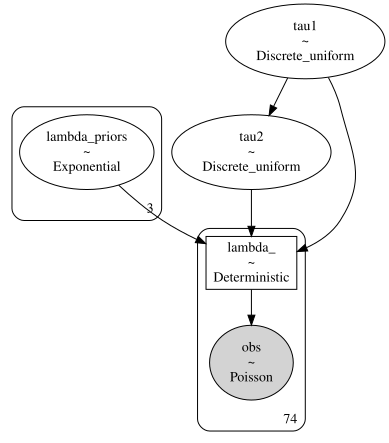

In [19]:
## Plot the graph of your model here
pm.model_to_graphviz(model)

### Lets look at the historgrams of tau1 and tau2 first

## Question:
### Do you think this data contains two or three arrival rates and why?

In my opinion, the data more clearly support two message arrival rates.
In the histogram for tau1, most samples are concentrated around index 45,
so the timing of the first change is relatively clear.
In contrast, the histogram for tau2 has two peaks, around indices 48 and 70.
In the first case, the second period lasts about two days, and in the
second case, it lasts about 25 days. The histograms for the second and
third rates also show two peaks.


**Therefore, based on the sampling results, I would choose two rates because
the first change point is relatively clear, while the second is less clear.**


### Exercise 2: The following problem is very similar to the one above. We wish to check arrival rates of pateint into an emergency department of a hospital. Again, we wish to know the switching points. Suppose you know there can be only between 2 to 4 arrival rates. Which one of these options you think is best.  

In [21]:

## load the data


colab = True
if colab:
  all_data = pkl.load(open("/content/drive/MyDrive/מודליים ביסיאניים/arrival_data1.pkl", 'rb'))
else:
  all_data = pkl.load(open('../data/arrival_data1.pkl', 'rb'))


all_data

array([ 0,  3,  1,  1,  1,  1,  2,  1,  0,  0,  0,  0,  1,  0,  3,  1,  1,
        1,  1,  0,  1,  1,  0,  1,  2,  0,  0,  2,  1,  1,  0,  0,  0,  0,
        3,  2,  0,  1,  1,  1,  0,  0,  2,  2,  1,  2,  0,  0,  1,  2,  0,
        1,  1,  0,  2,  0,  0,  0,  0,  1,  0,  1,  0,  0,  0,  1,  0,  0,
        1,  1,  2,  0,  0,  1,  0,  0,  1,  1,  0,  1,  0,  1,  0,  2,  0,
        3,  2,  0,  1,  3,  1,  1,  0,  0,  1,  2,  0,  1,  0,  2,  1,  0,
        3,  0,  0,  0,  2,  1,  1,  1,  2,  1,  2,  2,  0,  2,  0,  1,  2,
        0,  0,  2,  2,  1,  1,  1,  1,  0,  1,  1,  1,  0,  2,  0,  1,  0,
        0,  1,  0,  1,  2,  0,  0,  3,  0,  3,  2,  0,  0,  3,  3,  4,  3,
        4,  1,  5,  2,  5,  5,  3,  2,  4,  4,  4,  6,  7,  1,  2,  5,  5,
        5,  3,  6,  2,  2,  5,  9,  6,  5,  3,  9,  4,  2,  5,  7,  2,  7,
        6,  3,  5,  4,  4,  5,  1,  4, 10,  3,  3,  3,  2,  4,  6,  9,  5,
       11,  8,  7,  3,  9,  7, 15,  5,  7,  5, 10,  5,  6,  4,  4,  4,  8,
        7, 11,  6,  7,  2

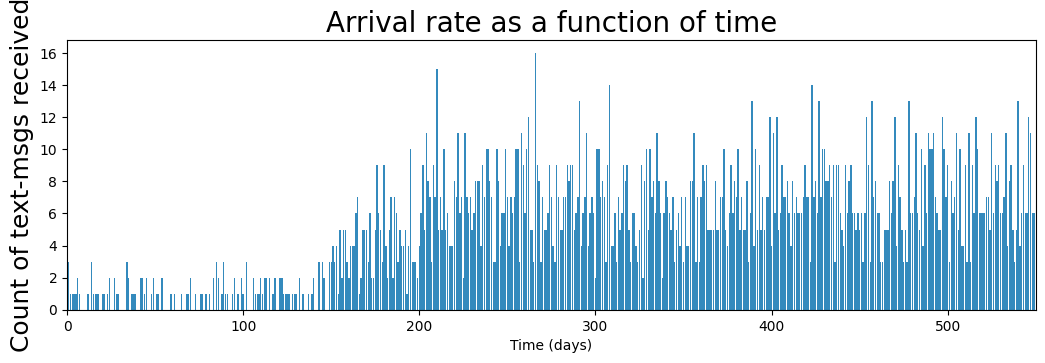

In [22]:
n_count_data = len(all_data)
plt.bar(np.arange(n_count_data), all_data, color="#348ABD")
plt.xlabel("Time (days)")
plt.ylabel("Count of text-msgs received", fontsize = 18)
plt.title("Arrival rate as a function of time", fontsize = 20)
plt.xlim(0, n_count_data);

## 2 arrival rates

In [23]:
## Your code here
with pm.Model() as model:
    alpha = 1.0 / all_data.mean()

    lambdas = pm.Exponential("lambda_priors", alpha, shape  =2)

    tau = pm.DiscreteUniform("tau", lower=0, upper=n_count_data - 1)

    idx = np.arange(n_count_data) # Index
    lambda_ = pm.math.switch(idx < tau, lambdas[0], lambdas[1])

    observation = pm.Poisson("obs", lambda_, observed=all_data)

    step = pm.Metropolis()
    trace_2 = pm.sample(5000, tune=1000, step=step)


Output()

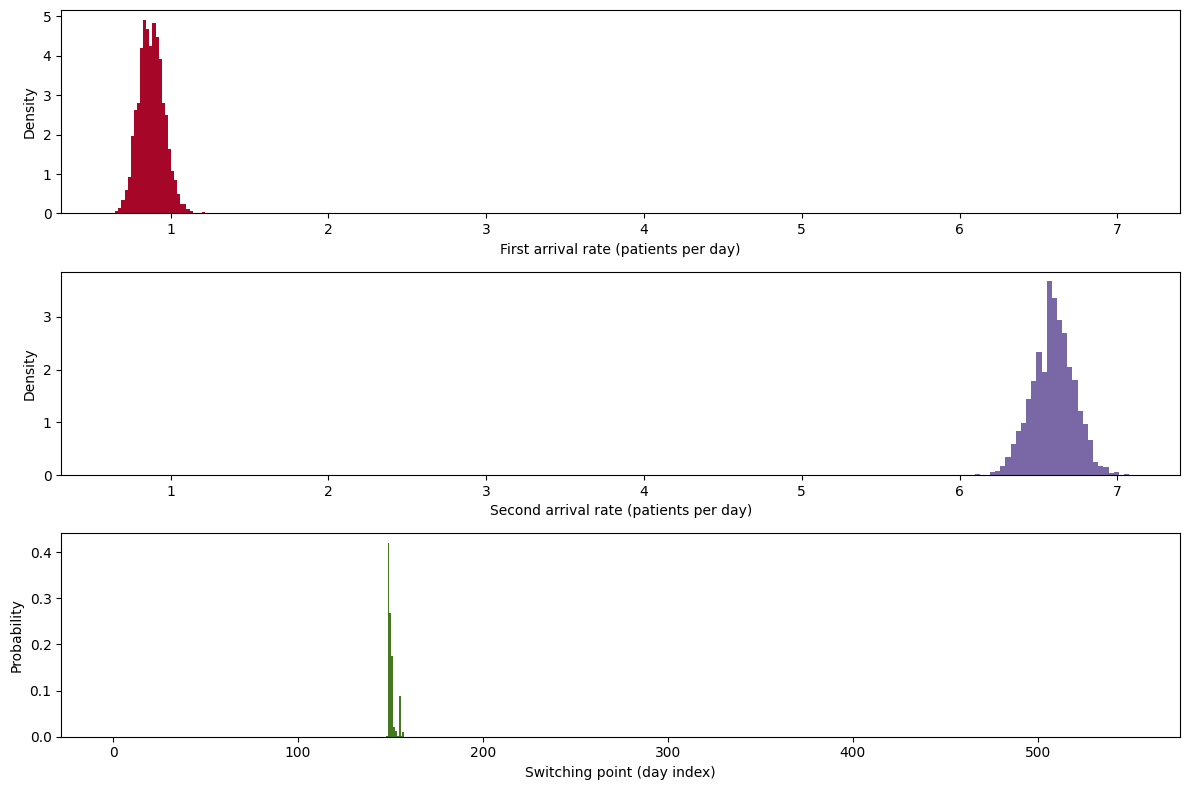

In [24]:
lambda_1_samples_2 = trace_2.posterior["lambda_priors"].values[:, :, 0].flatten()
lambda_2_samples_2 = trace_2.posterior["lambda_priors"].values[:, :, 1].flatten()
tau_samples_2 = np.array(trace_2.posterior["tau"]).flatten()

plt.figure(figsize=(12, 8))

ax1 = plt.subplot(311)
plt.hist(lambda_1_samples_2, bins=30, density=True, color="#A60628")
plt.xlabel("First arrival rate (patients per day)")
plt.ylabel("Density")

plt.subplot(312, sharex=ax1)
plt.hist(lambda_2_samples_2, bins=30, density=True, color="#7A68A6")
plt.xlabel("Second arrival rate (patients per day)")
plt.ylabel("Density")

plt.subplot(313)
w = np.ones_like(tau_samples_2) / len(tau_samples_2)
plt.hist(tau_samples_2, bins=np.arange(n_count_data + 1) - 0.5,
         weights=w, color="#467821")
plt.xlabel("Switching point (day index)")
plt.ylabel("Probability")

plt.tight_layout()
plt.show()

## 3 Arrival rates

In [25]:
## Your code here
with pm.Model() as model_3:
    alpha = 1.0 / all_data.mean()

    lambdas = pm.Exponential("lambda_priors", alpha, shape=3)

    tau1 = pm.DiscreteUniform("tau1", lower=1, upper=n_count_data - 2)
    tau2 = pm.DiscreteUniform("tau2", lower=tau1 + 1, upper=n_count_data - 1)

    idx = np.arange(n_count_data)
    lambda_ = pm.Deterministic(
        "lambda_",
        pm.math.switch(
            idx < tau1,
            lambdas[0],
            pm.math.switch(idx < tau2, lambdas[1], lambdas[2])
        )
    )

    observation = pm.Poisson("obs", lambda_, observed=all_data)

    step = pm.Metropolis()
    trace_3 = pm.sample(5000, tune=1000, step=step)


Output()

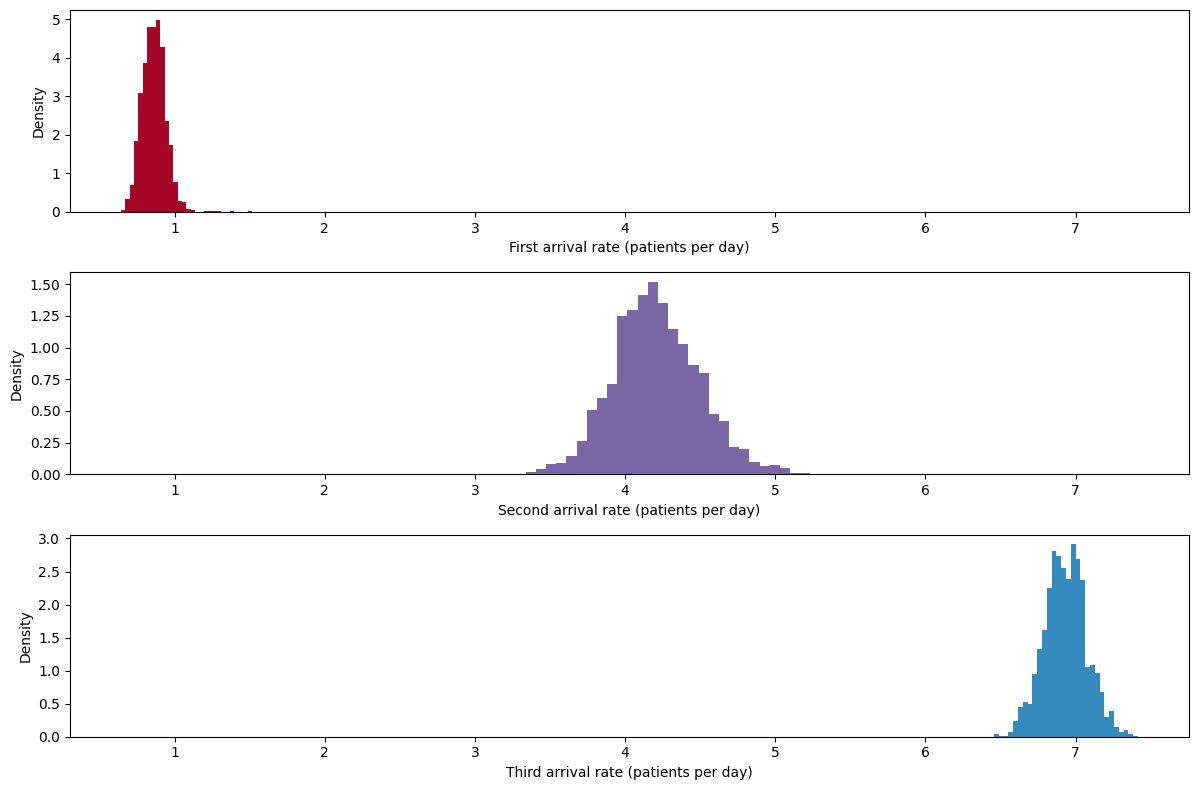

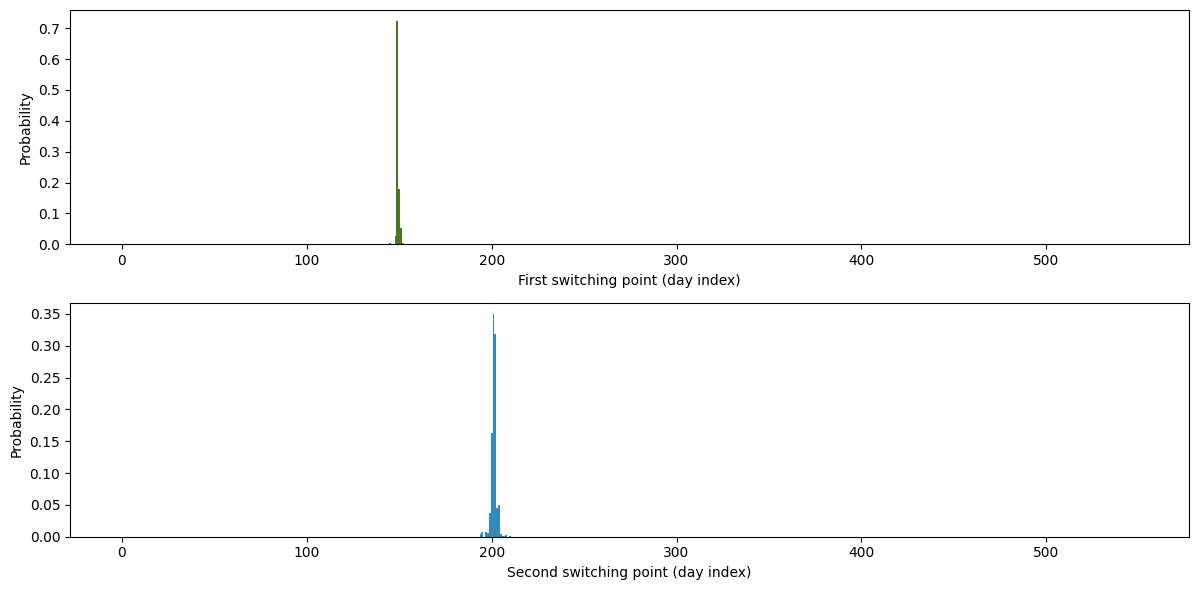

In [26]:
lambda_samples_3 = trace_3.posterior["lambda_priors"].values

lambda_1_samples_3 = lambda_samples_3[:, :, 0].flatten()
lambda_2_samples_3 = lambda_samples_3[:, :, 1].flatten()
lambda_3_samples_3 = lambda_samples_3[:, :, 2].flatten()

tau1_samples_3 = trace_3.posterior["tau1"].values.flatten()
tau2_samples_3 = trace_3.posterior["tau2"].values.flatten()

# Histograms of the three arrival rates
plt.figure(figsize=(12, 8))

ax1 = plt.subplot(311)
plt.hist(lambda_1_samples_3, bins=30, density=True, color="#A60628")
plt.xlabel("First arrival rate (patients per day)")
plt.ylabel("Density")

plt.subplot(312, sharex=ax1)
plt.hist(lambda_2_samples_3, bins=30, density=True, color="#7A68A6")
plt.xlabel("Second arrival rate (patients per day)")
plt.ylabel("Density")

plt.subplot(313, sharex=ax1)
plt.hist(lambda_3_samples_3, bins=30, density=True, color="#348ABD")
plt.xlabel("Third arrival rate (patients per day)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

# Histograms of the two switching points
day_bins = np.arange(n_count_data + 1) - 0.5

plt.figure(figsize=(12, 6))

plt.subplot(211)
w = np.ones_like(tau1_samples_3) / len(tau1_samples_3)
plt.hist(tau1_samples_3, bins=day_bins, weights=w, color="#467821")
plt.xlabel("First switching point (day index)")
plt.ylabel("Probability")

plt.subplot(212)
w = np.ones_like(tau2_samples_3) / len(tau2_samples_3)
plt.hist(tau2_samples_3, bins=day_bins, weights=w, color="#348ABD")
plt.xlabel("Second switching point (day index)")
plt.ylabel("Probability")

plt.tight_layout()
plt.show()

## 4 arrival rates

In [27]:
## Your code here
with pm.Model() as model_4:
    alpha = 1.0 / all_data.mean()

    lambdas = pm.Exponential("lambda_priors", alpha, shape=4)

    tau1 = pm.DiscreteUniform("tau1", lower=1, upper=n_count_data - 3)
    tau2 = pm.DiscreteUniform("tau2", lower=tau1 + 1, upper=n_count_data - 2)
    tau3 = pm.DiscreteUniform("tau3", lower=tau2 + 1, upper=n_count_data - 1)

    idx = np.arange(n_count_data)
    lambda_ = pm.Deterministic(
        "lambda_",
        pm.math.switch(
            idx < tau1,
            lambdas[0],
            pm.math.switch(
                idx < tau2,
                lambdas[1],
                pm.math.switch(idx < tau3, lambdas[2], lambdas[3])
            )
        )
    )

    observation = pm.Poisson("obs", lambda_, observed=all_data)

    step = pm.Metropolis()
    trace_4 = pm.sample(5000, tune=1000, step=step)



Output()

ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


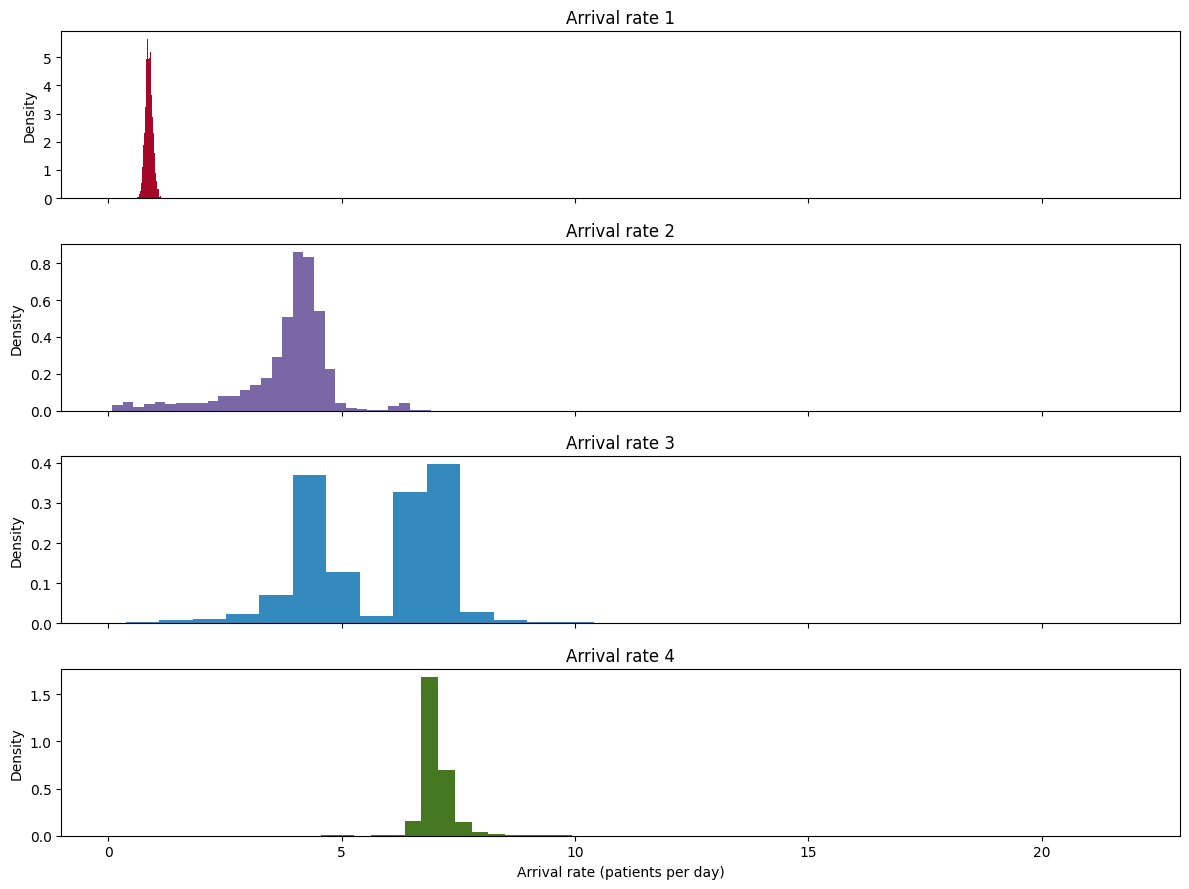

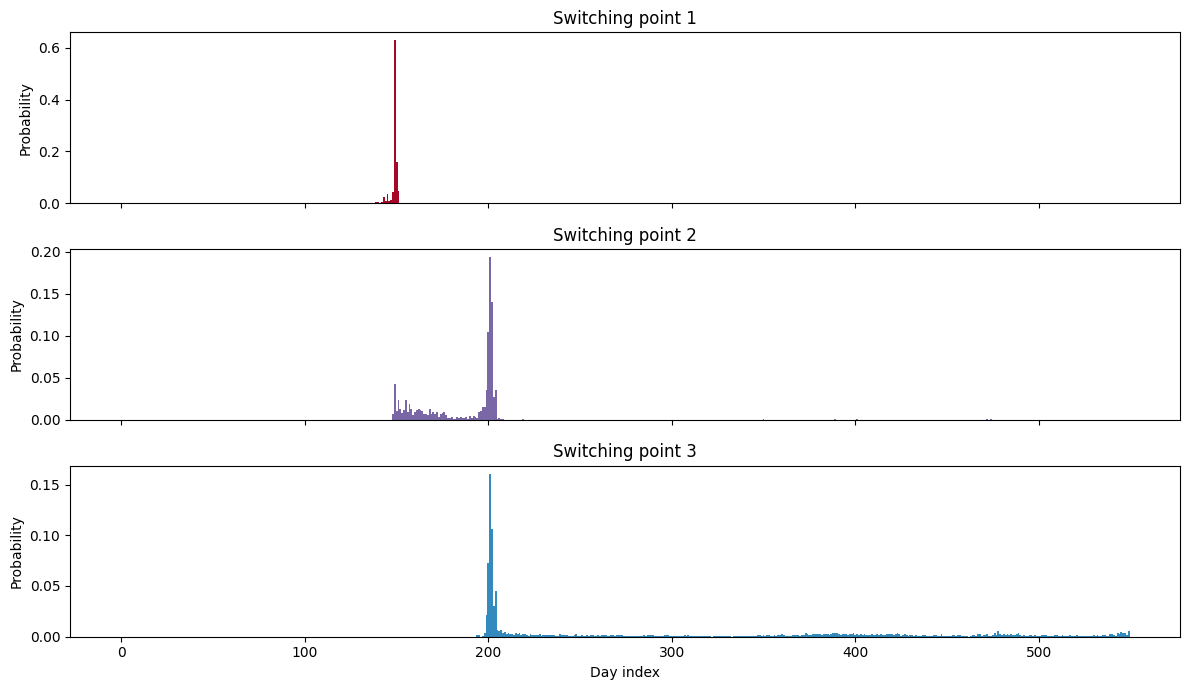

In [28]:
lambda_samples_4 = trace_4.posterior["lambda_priors"].values

# Histograms of the four arrival rates
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
colors = ["#A60628", "#7A68A6", "#348ABD", "#467821"]

for i, ax in enumerate(axes):
    ax.hist(lambda_samples_4[:, :, i].flatten(),
            bins=30, density=True, color=colors[i])
    ax.set_title(f"Arrival rate {i + 1}")
    ax.set_ylabel("Density")

axes[-1].set_xlabel("Arrival rate (patients per day)")
plt.tight_layout()
plt.show()

# Histograms of the three switching points
day_bins = np.arange(n_count_data + 1) - 0.5
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

for i, ax in enumerate(axes, start=1):
    tau_samples = trace_4.posterior[f"tau{i}"].values.flatten()
    w = np.ones_like(tau_samples) / len(tau_samples)
    ax.hist(tau_samples, bins=day_bins, weights=w, color=colors[i - 1])
    ax.set_title(f"Switching point {i}")
    ax.set_ylabel("Probability")

axes[-1].set_xlabel("Day index")
plt.tight_layout()
plt.show()

## Exercise 2 Conclusion

Based on the histograms, I think the model with three arrival rates best describes how the rate of patient arrivals at the emergency department changed over time. In the two rate model, the first rate is concentrated around 0.9 patients per day, with a smaller peak around 1.7, while the second rate is concentrated around 6.6 patients per day. Most samples place the change point near day index 150. This model captures a clear increase in arrivals, but it uses a single rate for the entire period after the change, combining the intermediate and later periods. In the three-rate model, the first rate is centered around 0.9 patients per day, the second around 4.2, and the third around 6.9. The three distributions show very little overlap, and the two change points are concentrated near day indices 149 and 200. This identifies an intermediate period of about 50 days, during which the arrival rate was about four patients per day before rising to about seven. In the four rate model, the first rate remains concentrated around 0.9 patients per day, and the fourth is centered around 7. The second rate has two peaks, around 1 and 4.2, while the third rate has two peaks, around 4.2 and 6.8. Some of these values overlap with the rates of adjacent periods. The change points are also less clearly defined in this model. The second change point has peaks near day indices 150 and 200, and the third has a peak near 200, with other samples spread across later days. I would therefore choose the three rate model because it identifies an intermediate period with a distinct arrival rate and two clearly defined change points. The four rate model provides weaker evidence for an additional period with its own distinct rate.

**Preferred model: The model with three arrival rates.**